In [1]:
%pip install pandas matplotlib scikit-learn

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 24.0 -> 26.3
[notice] To update, run: C:\Users\Ana Kelly\AppData\Local\Microsoft\WindowsApps\PythonSoftwareFoundation.Python.3.11_qbz5n2kfra8p0\python.exe -m pip install --upgrade pip


Formato: (303, 14)
Valores ausentes:
 ca      4
thal    2
dtype: int64

Target original:
 target
0    164
1     55
2     36
3     35
4     13
Name: count, dtype: int64

Target binarizado:
 target
0    164
1    139
Name: count, dtype: int64

Treino: 242 | Teste: 61

Tarefa 1 - iterações até a convergência: 5

Tarefa 2 - métricas no teste:
  Acurácia: 0.8689
  Precisão: 0.8125
  Recall:   0.9286
  F1-score: 0.8667
  AUC:      0.9513


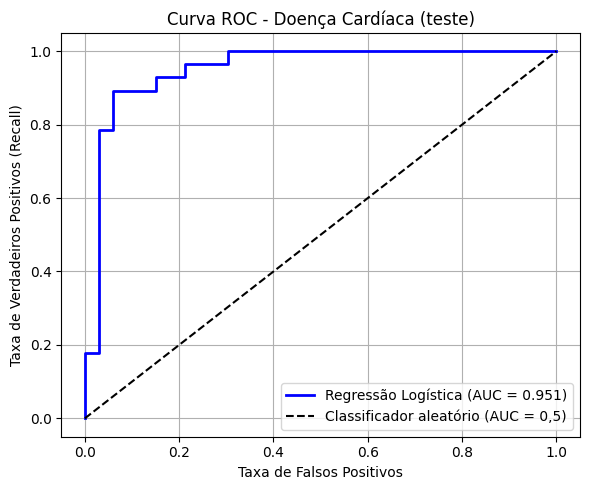

In [2]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, f1_score, precision_score,
                             recall_score, roc_auc_score, roc_curve)
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

URL = ("https://archive.ics.uci.edu/ml/machine-learning-databases/"
       "heart-disease/processed.cleveland.data")
COLUNAS = ["age", "sex", "cp", "trestbps", "chol", "fbs", "restecg",
           "thalach", "exang", "oldpeak", "slope", "ca", "thal", "target"]
PASTA_IMAGENS = Path("imagens")
PASTA_IMAGENS.mkdir(exist_ok=True)

# Carregar o dataset Cleveland direto da internet
df = pd.read_csv(URL, header=None, names=COLUNAS, na_values="?")
print("Formato:", df.shape)
ausentes = df.isna().sum()
print("Valores ausentes:\n", ausentes[ausentes > 0])

# Binarização do alvo: 0 = sem doença, 1-4 = com doença
print("\nTarget original:\n", df["target"].value_counts().sort_index())
df["target"] = (df["target"] > 0).astype(int)
print("\nTarget binarizado:\n", df["target"].value_counts().sort_index())

# Divisão treino (80%) e teste (20%), estratificada
X = df.drop(columns="target")
y = df["target"]
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42)
print(f"\nTreino: {len(X_train)} | Teste: {len(X_test)}")

# Tratamento de valores ausentes (ajuste só no treino)
imputer = SimpleImputer(strategy="most_frequent")
X_train = imputer.fit_transform(X_train)
X_test = imputer.transform(X_test)

# Padronização z-score (ajuste só no treino)
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

# Tarefa 1: treinar a regressão logística
model = LogisticRegression(solver="liblinear", random_state=42, max_iter=1000)
model.fit(X_train, y_train)
print("\nTarefa 1 - iterações até a convergência:", int(model.n_iter_[0]))

# Tarefa 2: métricas no conjunto de teste
y_pred = model.predict(X_test)
y_proba = model.predict_proba(X_test)[:, 1]
auc = roc_auc_score(y_test, y_proba)
print("\nTarefa 2 - métricas no teste:")
print(f"  Acurácia: {accuracy_score(y_test, y_pred):.4f}")
print(f"  Precisão: {precision_score(y_test, y_pred):.4f}")
print(f"  Recall:   {recall_score(y_test, y_pred):.4f}")
print(f"  F1-score: {f1_score(y_test, y_pred):.4f}")
print(f"  AUC:      {auc:.4f}")

# Curva ROC
fpr, tpr, _ = roc_curve(y_test, y_proba)
plt.figure(figsize=(6, 5))
plt.plot(fpr, tpr, color="blue", lw=2, label=f"Regressão Logística (AUC = {auc:.3f})")
plt.plot([0, 1], [0, 1], "k--", label="Classificador aleatório (AUC = 0,5)")
plt.xlabel("Taxa de Falsos Positivos")
plt.ylabel("Taxa de Verdadeiros Positivos (Recall)")
plt.title("Curva ROC - Doença Cardíaca (teste)")
plt.legend(loc="lower right")
plt.grid(True)
plt.tight_layout()
plt.savefig(PASTA_IMAGENS / "roc.png", dpi=120)
plt.show()